<a href="https://colab.research.google.com/github/lazaroninamiguel-dot/mchv502-cuencas/blob/main/S10/S10.2_evento_extremo/notebook/S10.2_evento_extremo_MDD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# paso 0 cargar las libreria
import ee # plataforma que mas facilmente me da los datos y mas potente para esto.
import requests
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# paso 1 como usare GEE conectarme a GEE y autenticarme
try:
    ee.Initialize(project='catie-cuencas-miguel') # <- ID de mi Projecto GEE
except Exception:
    ee.Authenticate()
    ee.Initialize(project='catie-cuencas-miguel')

print('Eart Engine listo')

Eart Engine listo


In [3]:

# buena practica es. parametrizar lo que vamos a extraer

evento = 'MDD_2021' # Inundacion de Madre de Dios 2021
fecha1 = '2021-02-08'
fecha2 = '2021-02-22'

# Earth Engine excluye la fecha final, asi que se le suma un dia
fin_ee = (pd.Timestamp(fecha2) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
print(f'{evento}:del {fecha1} al {fecha2} fecha para GEE: {fin_ee}')

MDD_2021:del 2021-02-08 al 2021-02-22 fecha para GEE: 2021-02-23


In [4]:
estaciones = pd.DataFrame([
    # estacion,              lat,      lon,     zona
    ('Puerto Maldonado',    -12.587, -69.209, 'Afectada'),  # SENAMHI 000808
    ('Laberinto',           -12.718, -69.592, 'Afectada'),  # virtual
    ('Malinowsky',          -12.934, -69.518, 'Afectada'),  # SENAMHI 47E8336C
    ('Alto libertad km 98', -12.898, -69.945, 'Afectada'),  # virtual (verificar)
    ('Mazuko',              -13.095, -70.380, 'Afectada'),  # virtual
    ('Huepetuhe',           -12.995, -70.535, 'Afectada'),  # virtual
    ('Boca Colorado',       -12.485, -70.515, 'Afectada'),  # virtual
    ('Iberia',              -11.410, -69.490, 'Afectada'),  # virtual
    ('Iñapari',             -10.956, -69.578, 'Afectada'),  # SENAMHI 000590
    ('Quincemil',           -13.229, -70.754, 'Entrada'),   # SENAMHI 000693
    ('San Gabán',           -13.461, -70.410, 'Entrada'),   # SENAMHI 156401
    ('Tambopata (S.J. Oro)',-14.225, -69.162, 'Entrada'),   # SENAMHI 000790
    ('Salvación',           -12.831, -71.364, 'Control'),   # SENAMHI 47E8201A
    ('Granja Kayra (Cusco)',-13.557, -71.875, 'Control'),   # SENAMHI 000607
    ('Sicuani',             -14.237, -71.237, 'Control'),   # SENAMHI 000759
    ('Juliaca',             -15.444, -70.208, 'Control'),   # SENAMHI 007454
], columns=['estacion', 'lat', 'lon', 'zona'])

In [5]:
estaciones

,estacion,lat,lon,zona
0,Puerto Maldonado,-12.587,-69.209,Afectada
1,Laberinto,-12.718,-69.592,Afectada
2,Malinowsky,-12.934,-69.518,Afectada
3,Alto libertad km 98,-12.898,-69.945,Afectada
4,Mazuko,-13.095,-70.380,Afectada
5,Huepetuhe,-12.995,-70.535,Afectada
6,Boca Colorado,-12.485,-70.515,Afectada
7,Iberia,-11.410,-69.490,Afectada
8,Iñapari,-10.956,-69.578,Afectada
9,Quincemil,-13.229,-70.754,Entrada


In [6]:
# convertirlas a un geopandas para que reconozca la geometria
puntos =  gpd.GeoDataFrame(estaciones, geometry = gpd.points_from_xy(estaciones.lon, estaciones.lat), crs=4326)
puntos.to_file(f'estaciones_{evento}.geojson') # para revisar en QGIS o geolibre.app
puntos

,estacion,lat,lon,zona,geometry
0,Puerto Maldonado,-12.587,-69.209,Afectada,POINT (-69.209 -12.587)
1,Laberinto,-12.718,-69.592,Afectada,POINT (-69.592 -12.718)
2,Malinowsky,-12.934,-69.518,Afectada,POINT (-69.518 -12.934)
3,Alto libertad km 98,-12.898,-69.945,Afectada,POINT (-69.945 -12.898)
4,Mazuko,-13.095,-70.380,Afectada,POINT (-70.38 -13.095)
5,Huepetuhe,-12.995,-70.535,Afectada,POINT (-70.535 -12.995)
6,Boca Colorado,-12.485,-70.515,Afectada,POINT (-70.515 -12.485)
7,Iberia,-11.410,-69.490,Afectada,POINT (-69.49 -11.41)
8,Iñapari,-10.956,-69.578,Afectada,POINT (-69.578 -10.956)
9,Quincemil,-13.229,-70.754,Entrada,POINT (-70.754 -13.229)


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

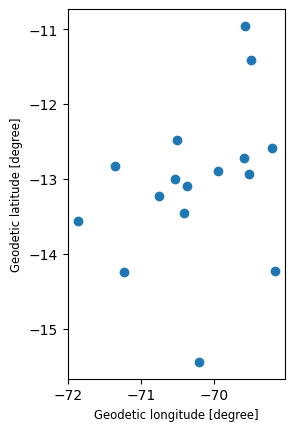

In [7]:
puntos.plot()

In [8]:
# estraer desde el dataset de GEE los valores historicos desde fecha1 a fecha2
puntos_ee = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([fila.lon, fila.lat]), {'estacion': fila.estacion})
    for fila in estaciones.itertuples()
])

In [9]:
# extraer filtrando los datos de gee desde fecha1 hasta fecha2
# referencia. https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY
chirps_evento = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
    .filterDate(fecha1, fin_ee) # filtro de fecha
    .select('precipitation')) # seleccionando la banda


In [10]:
def muestrear(imagen):
    fecha = imagen.date().format('YYYY-MM-dd')
    valores = imagen.reduceRegions(collection=puntos_ee, reducer=ee.Reducer.first(), scale=5566)
    return valores.map(lambda f: f.set('fecha', fecha))

muestras = chirps_evento.map(muestrear).flatten().getInfo()

largo = pd.DataFrame([f['properties'] for f in muestras['features']])
largo = largo.rename(columns={'first': 'lluvia_mm'})  # Corregido de 'firs' a 'first'

tabla = largo.pivot(index='fecha', columns='estacion', values='lluvia_mm')  # Corregido de 'table' a 'tabla'
tabla = tabla[estaciones['estacion']].round(1) # mismo orden que la lista

tabla.to_csv(f'lluvia_diaria_{evento}.csv')
tabla

estacion,Puerto Maldonado,Laberinto,Malinowsky,Alto libertad km 98,Mazuko,Huepetuhe,Boca Colorado,Iberia,Iñapari,Quincemil,San Gabán,Tambopata (S.J. Oro),Salvación,Granja Kayra (Cusco),Sicuani,Juliaca
fecha,,,,,,,,,,,,,,,,
2021-02-08,26.6,41.2,32.5,29.1,49.6,48.3,40.1,22.4,36.1,56.2,25.1,0.0,49.0,15.6,0.0,3.5
2021-02-09,0.0,0.0,0.0,9.7,0.0,0.0,0.0,44.8,54.2,0.0,0.0,7.6,12.2,0.0,0.0,3.5
2021-02-10,39.8,20.6,32.5,19.4,37.2,80.5,10.0,0.0,18.1,70.3,62.9,12.6,36.7,11.7,22.6,3.5
2021-02-11,81.7,40.5,65.6,66.5,68.2,42.0,46.5,55.1,19.4,21.6,44.2,26.4,52.6,11.6,9.0,4.7
2021-02-12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0
2021-02-13,0.0,13.5,16.4,0.0,0.0,0.0,0.0,18.4,19.4,21.6,0.0,0.0,26.3,5.8,0.0,2.3
2021-02-14,20.4,67.5,82.0,66.5,68.2,84.1,31.0,9.2,9.7,64.8,44.2,17.6,26.3,5.8,13.5,0.0
2021-02-15,20.4,27.0,16.4,66.5,68.2,63.0,62.0,0.0,9.7,64.8,88.3,35.2,65.8,11.6,4.5,2.3
2021-02-16,25.9,0.0,14.5,0.0,46.9,0.0,16.2,10.9,10.8,0.0,13.5,0.0,11.4,0.0,0.0,0.0


In [11]:
# ya es una dataframe normal podemos calcular con los datos
resumen = estaciones [['estacion', 'zona', 'lat', 'lon']].copy() # copia del dataframe de estaciones (pandas) de nombre resumen
resumen

,estacion,zona,lat,lon
0,Puerto Maldonado,Afectada,-12.587,-69.209
1,Laberinto,Afectada,-12.718,-69.592
2,Malinowsky,Afectada,-12.934,-69.518
3,Alto libertad km 98,Afectada,-12.898,-69.945
4,Mazuko,Afectada,-13.095,-70.380
5,Huepetuhe,Afectada,-12.995,-70.535
6,Boca Colorado,Afectada,-12.485,-70.515
7,Iberia,Afectada,-11.410,-69.490
8,Iñapari,Afectada,-10.956,-69.578
9,Quincemil,Entrada,-13.229,-70.754


In [12]:
# agrego una columna llamada total_mm con la suma de los valores de la tabla
resumen['total_mm'] = tabla.sum().round(1).values
resumen['max_diario_mm'] = tabla.max().round(1).values
resumen['dia_max'] = tabla.idxmax().values

resumen.sort_values('total_mm', ascending = False) # en forma decendente

,estacion,zona,lat,lon,total_mm,max_diario_mm,dia_max
4,Mazuko,Afectada,-13.095,-70.380,575.9,140.8,2021-02-18
5,Huepetuhe,Afectada,-12.995,-70.535,539.4,149.0,2021-02-18
9,Quincemil,Entrada,-13.229,-70.754,517.3,80.9,2021-02-18
10,San Gabán,Entrada,-13.461,-70.410,507.1,94.3,2021-02-18
3,Alto libertad km 98,Afectada,-12.898,-69.945,455.9,105.3,2021-02-18
2,Malinowsky,Afectada,-12.934,-69.518,403.8,82.0,2021-02-14
1,Laberinto,Afectada,-12.718,-69.592,372.8,104.9,2021-02-18
12,Salvación,Control,-12.831,-71.364,357.8,65.8,2021-02-15
6,Boca Colorado,Afectada,-12.485,-70.515,348.4,81.2,2021-02-18
0,Puerto Maldonado,Afectada,-12.587,-69.209,297.4,81.7,2021-02-11


In [13]:
resumen

,estacion,zona,lat,lon,total_mm,max_diario_mm,dia_max
0,Puerto Maldonado,Afectada,-12.587,-69.209,297.4,81.7,2021-02-11
1,Laberinto,Afectada,-12.718,-69.592,372.8,104.9,2021-02-18
2,Malinowsky,Afectada,-12.934,-69.518,403.8,82.0,2021-02-14
3,Alto libertad km 98,Afectada,-12.898,-69.945,455.9,105.3,2021-02-18
4,Mazuko,Afectada,-13.095,-70.380,575.9,140.8,2021-02-18
5,Huepetuhe,Afectada,-12.995,-70.535,539.4,149.0,2021-02-18
6,Boca Colorado,Afectada,-12.485,-70.515,348.4,81.2,2021-02-18
7,Iberia,Afectada,-11.410,-69.490,257.9,55.1,2021-02-11
8,Iñapari,Afectada,-10.956,-69.578,286.6,54.2,2021-02-09
9,Quincemil,Entrada,-13.229,-70.754,517.3,80.9,2021-02-18


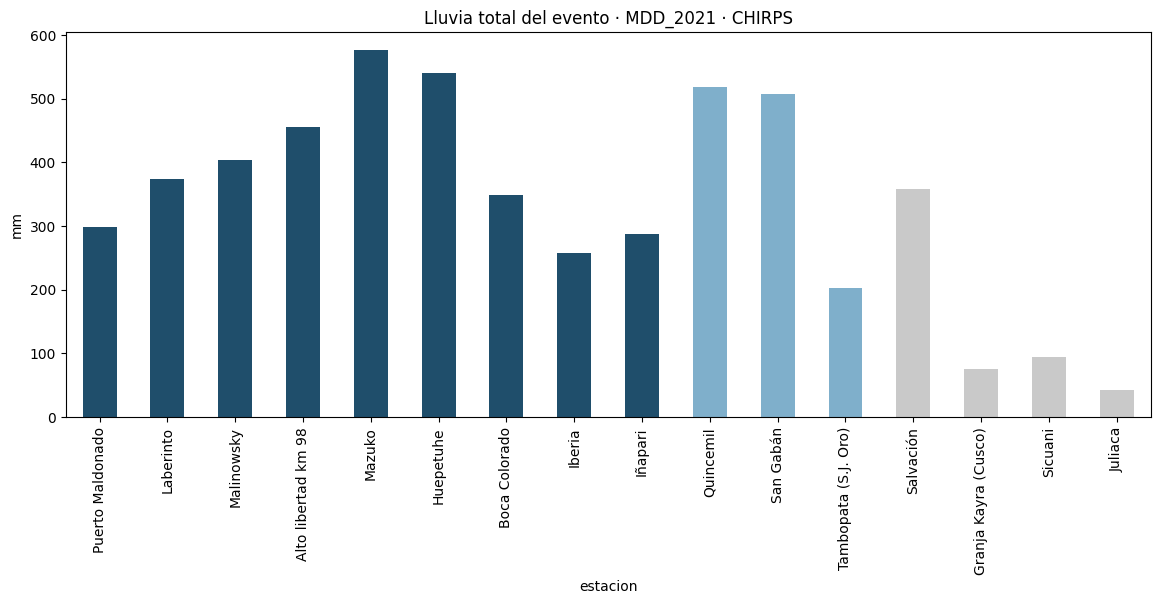

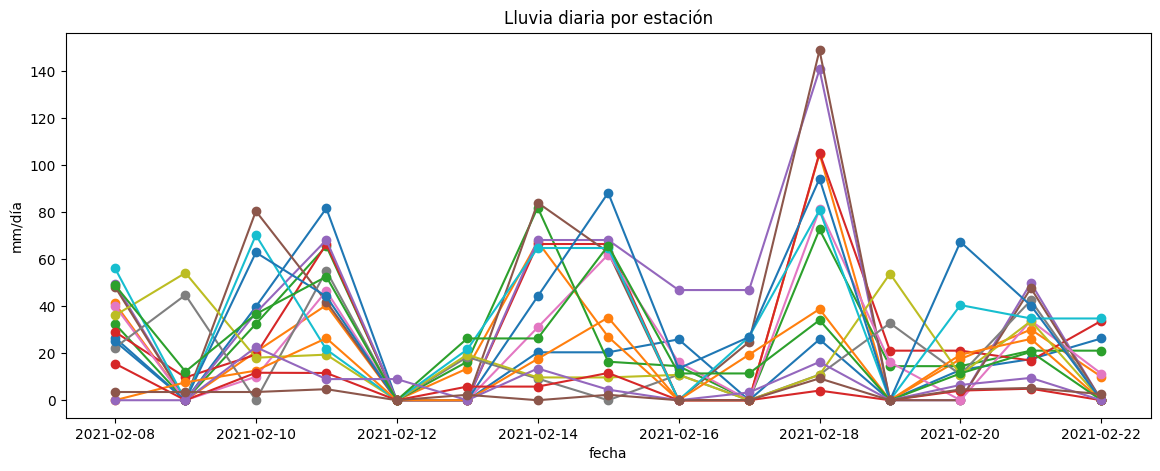

In [14]:
colores = resumen['zona'].map({'Afectada': '#1F4E6B', 'Entrada': '#7FAFCB', 'Control': '#C9C9C9'})
resumen.plot(x='estacion', y='total_mm', kind='bar', color=colores, legend=False, figsize=(14, 5),
             title=f'Lluvia total del evento · {evento} · CHIRPS')
plt.ylabel('mm')
plt.show()

tabla.plot(figsize=(14, 5), marker='o', legend=False, title='Lluvia diaria por estación')
plt.ylabel('mm/día')
plt.show()

In [15]:
# que tan extremo fue este evento? como lo hacemos, comparando con los percentiles para cada sitio
# que necesito para calcular los percentiles: HISTORIA - DATOS HISTORICOS
# De donde salen? de la misma fuente de datos
# extraer filtrando los datos de gee desde fecha1 hasta fecha2 referencia.
# https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY

historico = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
                .filterDate('2000-01-01', '2024-12-31') # filtro de fecha (equivale a pedir datos hasta 2024-12-31) # 25 años
                .select('precipitation'))  # seleccionado la banda

In [16]:
solo_dias_lluvia = historico.map(lambda img: img.updateMask(img.gt(2)))
percentiles = solo_dias_lluvia.reduce(ee.Reducer.percentile([90, 95, 99]))

In [17]:
# Extrae los valores de percentiles reduciendo las regiones de la colección de puntos usando la escala espacial en metros (5566 metros)
umbrales_ee = percentiles.reduceRegions(collection=puntos_ee, reducer=ee.Reducer.first(), scale=5566).getInfo()

# Convierte las propiedades de cada feature (elemento geográfico) obtenidas de GEE en un DataFrame de pandas
umbrales = pd.DataFrame([f['properties'] for f in umbrales_ee['features']])

# Renombra las columnas de la precipitación de los percentiles p90, p95 y p99 para facilitar su lectura
umbrales = umbrales.rename(columns={'precipitation_p90': 'P90', 'precipitation_p95': 'P95',
                                    'precipitation_p99': 'P99'})

# Redondea los valores numéricos de los percentiles a un solo decimal
umbrales[['P90', 'P95', 'P99']] = umbrales[['P90', 'P95', 'P99']].round(1)

# Muestra únicamente las columnas de interés: el nombre de la estación y sus respectivos percentiles (P90, P95, P99)
umbrales[['estacion', 'P90', 'P95', 'P99']]

,estacion,P90,P95,P99
0,Puerto Maldonado,37.6,47.4,72.6
1,Laberinto,43.6,55.4,82.6
2,Malinowsky,43.4,55.7,86.6
3,Alto libertad km 98,47.5,61.3,90.4
4,Mazuko,60.4,76.6,114.2
5,Huepetuhe,59.4,76.6,113.9
6,Boca Colorado,42.5,54.5,80.7
7,Iberia,31.3,40.8,62.4
8,Iñapari,32.2,41.2,66.4
9,Quincemil,55.5,71.5,107.6


In [18]:
def clasificar (mm, p90, p95, p99):
    if mm >= p99:
        return 'Extrema'
    elif mm >= p95:
        return 'Severa'
    elif mm >= p90:
         return 'Fuerte'
    return 'Normal'

In [19]:
resumen = resumen.merge(umbrales[['estacion', 'P90', 'P95', 'P99']], on='estacion')
resumen['categoria'] = [clasificar(r.max_diario_mm, r.P90, r.P95, r.P99) for r in resumen.itertuples()]
resumen['veces_P99'] = (resumen['max_diario_mm'] / resumen['P99']).round(1) #frecuencia en el período

In [20]:
resumen

,estacion,zona,lat,lon,total_mm,max_diario_mm,dia_max,P90,P95,P99,categoria,veces_P99
0,Puerto Maldonado,Afectada,-12.587,-69.209,297.4,81.7,2021-02-11,37.6,47.4,72.6,Extrema,1.1
1,Laberinto,Afectada,-12.718,-69.592,372.8,104.9,2021-02-18,43.6,55.4,82.6,Extrema,1.3
2,Malinowsky,Afectada,-12.934,-69.518,403.8,82.0,2021-02-14,43.4,55.7,86.6,Severa,0.9
3,Alto libertad km 98,Afectada,-12.898,-69.945,455.9,105.3,2021-02-18,47.5,61.3,90.4,Extrema,1.2
4,Mazuko,Afectada,-13.095,-70.380,575.9,140.8,2021-02-18,60.4,76.6,114.2,Extrema,1.2
5,Huepetuhe,Afectada,-12.995,-70.535,539.4,149.0,2021-02-18,59.4,76.6,113.9,Extrema,1.3
6,Boca Colorado,Afectada,-12.485,-70.515,348.4,81.2,2021-02-18,42.5,54.5,80.7,Extrema,1.0
7,Iberia,Afectada,-11.410,-69.490,257.9,55.1,2021-02-11,31.3,40.8,62.4,Severa,0.9
8,Iñapari,Afectada,-10.956,-69.578,286.6,54.2,2021-02-09,32.2,41.2,66.4,Severa,0.8
9,Quincemil,Entrada,-13.229,-70.754,517.3,80.9,2021-02-18,55.5,71.5,107.6,Severa,0.8


In [21]:
# descargar el raster de lluvia del evento (suma de los dias)
import rasterio
margen = 0.5  # grados alrededor de las estaciones
region = ee.Geometry.Rectangle([estaciones.lon.min()-margen, estaciones.lat.min()- margen,
                                estaciones.lon.max() + margen, estaciones.lat.max() + margen])

total = chirps_evento.sum().rename('lluvia_total_mm') ###suma de la serie
url_tif = total.getDownloadURL({'region': region, 'scale': 5566, 'crs': 'EPSG:4326', 'format': 'GEO_TIFF'})

archivo_tif = f'lluvia_total_{evento}.tif'
with open(archivo_tif, 'wb') as f:
    f.write(requests.get(url_tif, timeout=300).content)
print('Guardado:', archivo_tif)

Guardado: lluvia_total_MDD_2021.tif


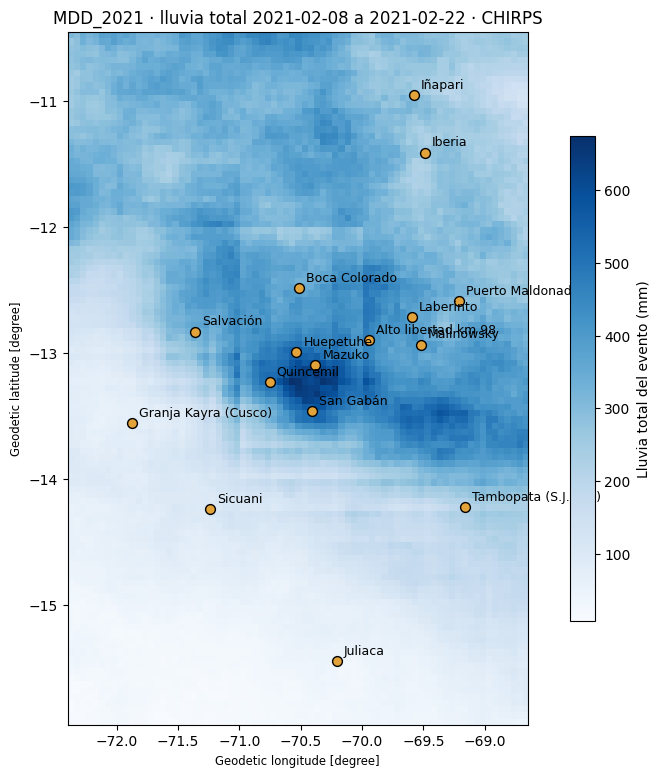

In [22]:
# abro este mismo geotiff y lo muestro en python, ademas como ya tengo las estaciones, tambien las muestro
with rasterio.open(archivo_tif) as src:
    lluvia = src.read(1)
    b = src.bounds

fig, ax = plt.subplots(figsize=(11, 9))
img = ax.imshow(lluvia, cmap='Blues', extent=[b.left, b.right, b.bottom, b.top])
plt.colorbar(img, ax=ax, label='Lluvia total del evento (mm)', shrink=0.7)

puntos.plot(ax=ax, color='#E3A33B', edgecolor='black', markersize=50)
for fila in estaciones.itertuples():
    ax.annotate(fila.estacion, (fila.lon, fila.lat), xytext=(5, 5), textcoords='offset points', fontsize=9)

ax.set_title(f'{evento} · lluvia total {fecha1} a {fecha2} · CHIRPS')
plt.show()

# las estaciones con sus totales y umbrales, para el SIG

puntos_resumen = puntos[['estacion','geometry']].merge(resumen, on='estacion')
puntos_resumen.to_file(f'estaciones_resumen_{evento}.geojson')

In [23]:
import numpy as np
from rasterio.mask import mask
from rasterio.plot import show

xs_est = resumen['lon'].values
ys_est = resumen['lat'].values
z_est = resumen['total_mm'].values

def idw(x, y, xs, ys, zs, potencia):
    """Interpolación IDW. Distancias en grados: aceptable en el trópico para una zona pequeña."""
    d = np.sqrt((xs[None, :] - x[:, None])**2 + (ys[None, :] - y[:, None])**2)
    d = np.maximum(d, 1e-6)
    w = 1 / d**potencia
    return (w * zs).sum(axis=1) / w.sum(axis=1)

filas = []
for p in [1, 1.5, 2, 2.5, 3]:
    errores = []
    for i in range(len(z_est)):
        resto = np.arange(len(z_est)) != i
        estimado = idw(xs_est[[i]], ys_est[[i]], xs_est[resto], ys_est[resto], z_est[resto], p)[0]
        errores.append(estimado - z_est[i])
    errores = np.array(errores)
    filas.append({'potencia': p,
                  'RMSE_mm': round(float(np.sqrt((errores**2).mean())), 1),
                  'sesgo_mm': round(float(errores.mean()), 1)})

validacion = pd.DataFrame(filas)
potencia = validacion.loc[validacion['RMSE_mm'].idxmin(), 'potencia']
print('Potencia óptima:', potencia)
validacion

Potencia óptima: 3.0


,potencia,RMSE_mm,sesgo_mm
0,1.0,148.8,45.0
1,1.5,141.3,60.0
2,2.0,136.6,69.2
3,2.5,133.5,74.0
4,3.0,130.9,76.2


Guardado: lluvia_total_idw_MDD_2021.tif


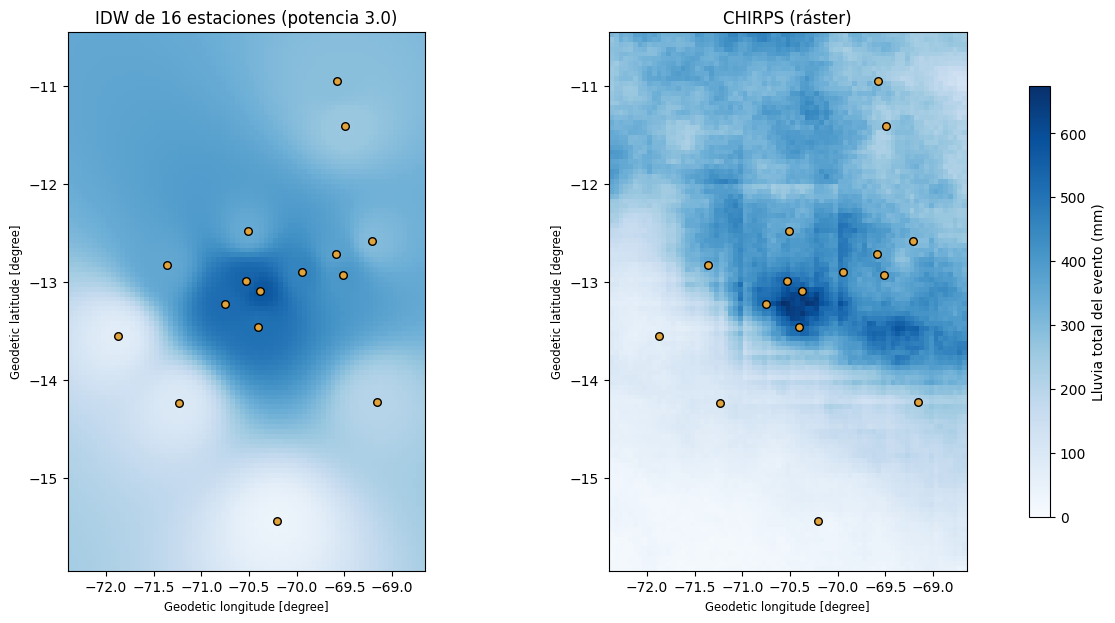

In [24]:
with rasterio.open(archivo_tif) as src:
    perfil = src.profile
    chirps_total = src.read(1, masked=True).filled(np.nan).astype('float32')
    filas_r, cols_r = np.indices(chirps_total.shape)
    lon_r, lat_r = rasterio.transform.xy(src.transform, filas_r.ravel(), cols_r.ravel())

idw_total = idw(np.array(lon_r), np.array(lat_r), xs_est, ys_est, z_est, potencia)
idw_total = idw_total.reshape(chirps_total.shape).astype('float32')

perfil.update(dtype='float32', count=1, nodata=-9999)
archivo_idw = f'lluvia_total_idw_{evento}.tif'
with rasterio.open(archivo_idw, 'w', **perfil) as dst:
    dst.write(idw_total, 1)
print('Guardado:', archivo_idw)

vmax = np.nanmax(chirps_total)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, datos, titulo in zip(axes, [idw_total, chirps_total],
                             [f'IDW de {len(z_est)} estaciones (potencia {potencia})', 'CHIRPS (ráster)']):
    img = ax.imshow(datos, cmap='Blues', vmin=0, vmax=vmax, extent=[b.left, b.right, b.bottom, b.top])
    puntos.plot(ax=ax, color='#E3A33B', edgecolor='black', markersize=30)
    ax.set_title(titulo)
plt.colorbar(img, ax=axes, label='Lluvia total del evento (mm)', shrink=0.8)
plt.show()